# Data Cleaning & Exploratory Data Analysis (EDA)


## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the dataset
`read_csv()` loads the CSV into a Pandas DataFrame. A DataFrame is a table of rows and columns.

In [ ]:
from pathlib import Path

file_path = Path("/content/Raw_Sales.csv")
if not file_path.exists():
    raise FileNotFoundError("Keep Raw_Sales.csv in the same folder as this notebook.")

raw_df = pd.read_csv(file_path)
df = raw_df.copy()

print("Original shape:", raw_df.shape)
display(raw_df.head())
raw_df.info()

Original shape: (301, 13)


,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Quantity,Unit Price,Discount,Sales,Profit
0,ORD0001,2026-01-29,C005,Kabir Mehta,Monitor,Electronics,North,Jaipur,5.00,"15,123.96",0.10,"68,057.82","15,420.48"
1,ORD0002,2026-05-31,C003,Rohan Verma,Monitor,Electronics,Central,Indore,6.00,"14,997.75",0.10,"80,987.85","22,750.71"
2,ORD0003,2026-03-10,C010,Sara Khan,Printer,Electronics,North,Delhi,6.00,"10,179.57",0.15,"51,915.81","14,663.56"
3,ORD0004,2026-07-30,C013,Reyansh Kapoor,Bookshelf,Furniture,East,Bhubaneswar,1.00,"6,755.55",0.05,"6,417.77","1,368.40"
4,ORD0005,2026-05-21,C008,Meera Nair,Printer,Electronics,North,Jaipur,4.00,"10,127.38",0.20,"32,407.62","10,927.18"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       300 non-null    object 
 1   Order Date     300 non-null    object 
 2   Customer ID    300 non-null    object 
 3   Customer Name  300 non-null    object 
 4   Product        300 non-null    object 
 5   Category       300 non-null    object 
 6   Region         300 non-null    object 
 7   City           300 non-null    object 
 8   Quantity       300 non-null    float64
 9   Unit Price     300 non-null    float64
 10  Discount       300 non-null    float64
 11  Sales          300 non-null    float64
 12  Profit         300 non-null    float64
dtypes: float64(5), object(8)
memory usage: 30.7+ KB


## 3. Basic statistics and first inspection

Use `shape`, `dtypes`, `describe()`, and `nunique()` to understand the dataset before making changes.

In [ ]:
print("Rows and columns:", df.shape)
display(df.describe(include="all").T)
display(df.nunique().to_frame("Unique values"))

Rows and columns: (301, 13)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,300,300,ORD0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,300,193,2026-05-31,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,300,20,C016,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,300,20,Myra Jain,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,300,11,Smartphone,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,300,3,Electronics,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,300,5,North,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,300,15,Chandigarh,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,300.00,NaN,NaN,NaN,3.80,2.04,1.00,2.00,4.00,6.00,7.00
Unit Price,300.00,NaN,NaN,NaN,"13,476.70","14,174.00",75.37,"2,584.14","9,611.45","14,741.05","54,866.23"


,Unique values
Order ID,300
Order Date,193
Customer ID,20
Customer Name,20
Product,11
Category,3
Region,5
City,15
Quantity,7
Unit Price,297


## 4. Missing values

A missing value means a field has no recorded value. First count missing values in each column and calculate the percentage.



In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
display(missing_summary)
print("Fully blank rows:", df.isna().all(axis=1).sum())

,Missing_Count,Missing_Percent
Order ID,1,0.33
Order Date,1,0.33
Customer ID,1,0.33
Customer Name,1,0.33
Product,1,0.33
Category,1,0.33
Region,1,0.33
City,1,0.33
Quantity,1,0.33
Unit Price,1,0.33


Fully blank rows: 1


### identify rows containing at least one missing value

In [ ]:
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows with one or more missing values:", len(rows_with_missing))
display(rows_with_missing.head())

Rows with one or more missing values: 1


,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,City,Quantity,Unit Price,Discount,Sales,Profit
300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Duplicate removal

A duplicate row repeats the same values across all columns. We count duplicates first, then remove exact duplicate rows.

In [ ]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df.shape)

Exact duplicate rows: 0
Shape after duplicate removal: (301, 13)


## 6. Data validation and standardization

Validation checks whether values have sensible formats and fall within expected rules. Here we:
- strip spaces from text values;
- convert dates into datetime values;
- convert measures into numeric values;
- check invalid dates and missing required fields;
- check non-positive quantities and negative sales/profit values for review.

A validation flag does not always mean the record is wrong; it tells us what to inspect.

In [ ]:
# Clean whitespace from text columns
text_columns = df.select_dtypes(include="object").columns
for column in text_columns:
    df[column] = df[column].str.strip()

# Convert date and numeric columns
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
numeric_columns = ["Quantity", "Unit Price", "Discount", "Sales", "Profit"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

validation_checks = {
    "Missing Order ID": df["Order ID"].isna().sum(),
    "Missing Customer ID": df["Customer ID"].isna().sum(),
    "Missing Product": df["Product"].isna().sum(),
    "Invalid Order Date": df["Order Date"].isna().sum(),
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "Negative Unit Price": (df["Unit Price"] < 0).sum(),
    "Negative Sales": (df["Sales"] < 0).sum(),
}
display(pd.Series(validation_checks, name="Count").to_frame())

,Count
Missing Order ID,1
Missing Customer ID,1
Missing Product,1
Invalid Order Date,1
Quantity <= 0,0
Negative Unit Price,0
Negative Sales,0


## 7. Apply cleaning decisions

Remove fully blank rows, standardize text, and remove exact duplicates. For this supplied dataset, the all-blank row is the identified missing-data issue. We keep any partially populated rows for review rather than silently deleting useful information.

In [ ]:
clean_df = raw_df.copy()
clean_df = clean_df.dropna(how="all")

for column in clean_df.select_dtypes(include="object").columns:
    clean_df[column] = clean_df[column].str.strip()

clean_df["Order Date"] = pd.to_datetime(clean_df["Order Date"], errors="coerce")
for column in ["Quantity", "Unit Price", "Discount", "Sales", "Profit"]:
    clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

clean_df = clean_df.drop_duplicates().copy()

print("Raw rows:", len(raw_df))
print("Clean rows:", len(clean_df))
print("Rows removed:", len(raw_df) - len(clean_df))
print("Remaining missing values:")
display(clean_df.isna().sum().to_frame("Missing_Count"))

Raw rows: 301
Clean rows: 300
Rows removed: 1
Remaining missing values:


,Missing_Count
Order ID,0
Order Date,0
Customer ID,0
Customer Name,0
Product,0
Category,0
Region,0
City,0
Quantity,0
Unit Price,0


## 8. Outlier detection using the IQR method

The interquartile range (IQR) is the distance between the 75th percentile (Q3) and 25th percentile (Q1). The common 1.5 × IQR rule flags unusually low or high values.



In [ ]:
outlier_results = []
for column in ["Quantity", "Unit Price", "Discount", "Sales", "Profit"]:
    values = clean_df[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flagged = ((values < lower_fence) | (values > upper_fence)).sum()

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Fence": lower_fence,
        "Upper_Fence": upper_fence,
        "Outlier_Count": int(flagged)
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

,Column,Q1,Q3,IQR,Lower_Fence,Upper_Fence,Outlier_Count
0,Quantity,2.00,6.00,4.00,-4.00,12.00,0
1,Unit Price,"2,584.14","14,741.05","12,156.91","-15,651.22","32,976.41",25
2,Discount,0.05,0.15,0.10,-0.10,0.30,0
3,Sales,"7,308.56","56,114.87","48,806.30","-65,900.90","129,324.33",31
4,Profit,"1,674.84","14,732.30","13,057.46","-17,911.35","34,318.49",27


### Visual check: sales distribution

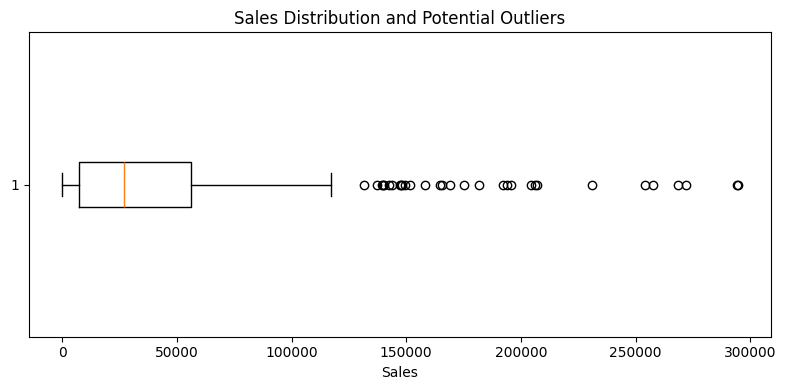

In [ ]:
plt.figure(figsize=(8, 4))
plt.boxplot(clean_df["Sales"].dropna(), vert=False)
plt.title("Sales Distribution and Potential Outliers")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

## 9. Basic statistics

Use mean, median, standard deviation, minimum, maximum, and quartiles to summarize numeric columns. The mean can be affected by unusually large values, so compare it with the median.

In [ ]:
basic_statistics = clean_df[["Quantity", "Unit Price", "Discount", "Sales", "Profit"]].describe().T
basic_statistics["Median"] = clean_df[["Quantity", "Unit Price", "Discount", "Sales", "Profit"]].median()
display(basic_statistics.round(2))

,count,mean,std,min,25%,50%,75%,max,Median
Quantity,300.00,3.80,2.04,1.00,2.00,4.00,6.00,7.00,4.00
Unit Price,300.00,"13,476.70","14,174.00",75.37,"2,584.14","9,611.46","14,741.05","54,866.23","9,611.46"
Discount,300.00,0.10,0.07,0.00,0.05,0.10,0.15,0.20,0.10
Sales,300.00,"45,501.29","57,167.30",66.91,"7,308.56","26,728.08","56,114.87","294,542.55","26,728.08"
Profit,300.00,"11,745.19","14,868.58",12.87,"1,674.84","7,323.22","14,732.30","104,453.09","7,323.22"


## 10. Correlation analysis

Correlation measures the strength and direction of a **linear relationship** between two numeric variables. It does not prove that one variable causes another.

A value near +1 indicates a strong positive linear relationship; near -1 indicates a strong negative relationship; near 0 indicates little linear relationship.

,Quantity,Unit Price,Discount,Sales,Profit
Quantity,1.00,-0.01,0.06,0.41,0.39
Unit Price,-0.01,1.00,-0.01,0.80,0.78
Discount,0.06,-0.01,1.00,-0.01,-0.02
Sales,0.41,0.80,-0.01,1.00,0.96
Profit,0.39,0.78,-0.02,0.96,1.00


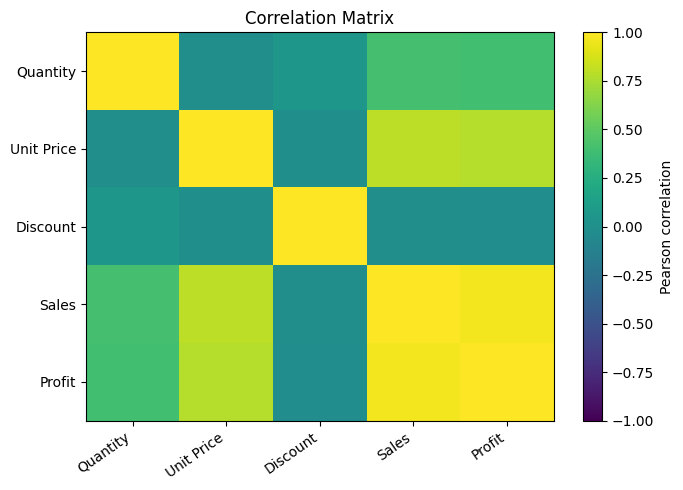

In [ ]:
correlation = clean_df[["Quantity", "Unit Price", "Discount", "Sales", "Profit"]].corr()
display(correlation.round(3))

plt.figure(figsize=(7, 5))
plt.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=35, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 11. Trend analysis

Convert the order date into a month period, then summarize revenue and profit by month. A line chart helps identify stronger and weaker months.

,Month,Revenue,Profit
0,2026-01,"1,597,108.36","388,548.67"
1,2026-02,"1,390,543.49","381,704.11"
2,2026-03,"1,825,138.79","445,849.21"
3,2026-04,"1,211,945.32","337,606.17"
4,2026-05,"2,126,367.77","549,087.70"
5,2026-06,"1,387,626.67","371,966.44"
6,2026-07,"1,254,996.17","313,686.74"
7,2026-08,"1,420,906.37","367,240.52"
8,2026-09,"821,466.33","203,326.26"
9,2026-10,"614,286.55","164,540.80"


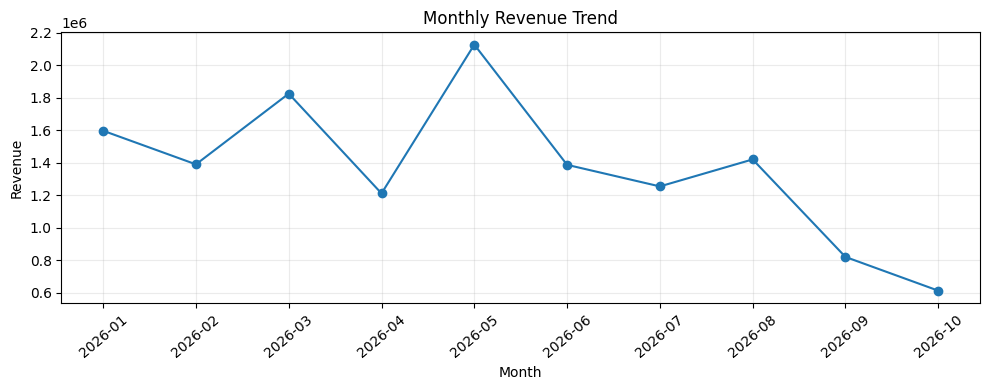

In [ ]:
monthly_trend = (
    clean_df.dropna(subset=["Order Date"])
    .assign(Month=lambda x: x["Order Date"].dt.to_period("M").astype(str))
    .groupby("Month")
    .agg(Revenue=("Sales", "sum"), Profit=("Profit", "sum"))
    .reset_index()
)
display(monthly_trend.round(2))

plt.figure(figsize=(10, 4))
plt.plot(monthly_trend["Month"], monthly_trend["Revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=40)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Business analysis: region, category, and product

In [ ]:
region_summary = clean_df.groupby("Region").agg(
    Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_values("Revenue", ascending=False)

category_summary = clean_df.groupby("Category").agg(
    Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
    Quantity_Sold=("Quantity", "sum")
).sort_values("Revenue", ascending=False)

product_summary = clean_df.groupby("Product").agg(
    Revenue=("Sales", "sum"), Profit=("Profit", "sum"),
    Quantity_Sold=("Quantity", "sum")
).sort_values("Revenue", ascending=False)

display(region_summary.round(2))
display(category_summary.round(2))
display(product_summary.head(10).round(2))

,Revenue,Profit,Orders
Region,,,
Central,"3,091,627.06","832,238.02",60
West,"2,874,608.31","700,393.46",59
South,"2,820,804.68","741,362.10",57
East,"2,745,064.20","721,987.43",56
North,"2,118,281.57","527,575.61",68


,Revenue,Profit,Quantity_Sold
Category,,,
Electronics,"10,722,020.45","2,762,200.85",580.00
Furniture,"2,909,199.51","756,179.67",358.00
Stationery,"19,165.86","5,176.10",203.00


,Revenue,Profit,Quantity_Sold
Product,,,
Laptop,"4,103,588.60","1,035,804.73",93.00
Smartphone,"3,820,864.22","977,222.70",153.00
Printer,"1,387,311.67","376,455.31",160.00
Desk,"1,383,710.21","357,625.30",128.00
Monitor,"1,236,396.41","326,736.61",94.00
Office Chair,"802,654.26","207,466.02",105.00
Bookshelf,"722,835.04","191,088.35",125.00
Headphones,"173,859.55","45,981.50",80.00
Notebook,"12,989.55","3,482.24",120.00


## 13. Complete the EDA task


In [ ]:
total_revenue = clean_df["Sales"].sum()
total_profit = clean_df["Profit"].sum()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Cleaned Records", "Unique Orders", "Unique Customers",
        "Total Revenue", "Total Profit", "Average Sales per Record",
        "Overall Profit Margin (%)"
    ],
    "Value": [
        len(clean_df),
        clean_df["Order ID"].nunique(),
        clean_df["Customer ID"].nunique(),
        total_revenue,
        total_profit,
        clean_df["Sales"].mean(),
        (total_profit / total_revenue * 100) if total_revenue else 0
    ]
})
display(kpi_summary)

,Metric,Value
0,Cleaned Records,300.00
1,Unique Orders,300.00
2,Unique Customers,20.00
3,Total Revenue,"13,650,385.82"
4,Total Profit,"3,523,556.62"
5,Average Sales per Record,"45,501.29"
6,Overall Profit Margin (%),25.81


In [ ]:
# Create one consolidated CSV instead of several separate result files
result_columns = ['Record_Type', 'Section', 'Metric', 'Value', 'Details', 'Order ID', 'Order Date', 'Customer ID', 'Customer Name', 'Product', 'Category', 'Region', 'City', 'Quantity', 'Unit Price', 'Discount', 'Sales', 'Profit']
result_rows = []

# Include every cleaned transaction row
for _, row in clean_df.iterrows():
    item = {'Record_Type': 'Cleaned_Data', 'Section': 'Cleaned Transactions'}
    item.update(row.to_dict())
    result_rows.append(item)

def add_result(section, metric, value, details=''):
    result_rows.append({'Record_Type': 'Summary', 'Section': section, 'Metric': metric, 'Value': value, 'Details': details})

# KPIs
for _, row in kpi_summary.iterrows():
    add_result('KPI', row['Metric'], row['Value'])

# Missing-value checks before and after cleaning
for column in raw_df.columns:
    add_result('Missing Values Before Cleaning', column, int(raw_df[column].isna().sum()))
for column in clean_df.columns:
    add_result('Missing Values After Cleaning', column, int(clean_df[column].isna().sum()))

# Outlier counts and IQR bounds
for _, row in outlier_summary.iterrows():
    add_result('Outlier Detection', row['Column'], int(row['Outlier_Count']), f"IQR lower={row['Lower_Fence']:.2f}; upper={row['Upper_Fence']:.2f}; retained for investigation")

# Descriptive statistics
for column in basic_statistics.index:
    for stat in basic_statistics.columns:
        add_result('Basic Statistics', f'{column} - {stat}', round(float(basic_statistics.loc[column, stat]), 4))

# Correlation matrix
for col_a in correlation.columns:
    for col_b in correlation.columns:
        add_result('Correlation', f'{col_a} vs {col_b}', round(float(correlation.loc[col_a, col_b]), 4), 'Pearson correlation; does not imply causation')

# Monthly, regional, category, and product summaries
for _, row in monthly_trend.iterrows():
    add_result('Monthly Trend', row['Month'], round(float(row['Revenue']), 2), f"Profit={row['Profit']:.2f}")
for section, summary in [('Region Performance', region_summary), ('Category Performance', category_summary), ('Product Performance', product_summary)]:
    for name, row in summary.iterrows():
        add_result(section, str(name), round(float(row['Revenue']), 2), f"Profit={row['Profit']:.2f}; quantity={int(row.get('Quantity', row.get('Quantity_Sold', 0)))}; unique orders={int(row.get('Orders', 0))}")

complete_results = pd.DataFrame(result_rows)
for column in result_columns:
    if column not in complete_results.columns:
        complete_results[column] = np.nan
complete_results = complete_results[result_columns]
complete_results.to_csv('Sales_EDA_Complete_Results.csv', index=False)
print('Saved one consolidated file: Sales_EDA_Complete_Results.csv')
print('It includes cleaned transactions and all summary analysis sections.')


Saved one consolidated file: Sales_EDA_Complete_Results.csv
It includes cleaned transactions and all summary analysis sections.
